# Eddy Alejandro Sangucho Coronel

# 02 Procesamiento de texto,recuperación secuencial e indexación

## Parte A. Corpus pequeño

### 1. Preparación del corpus

In [ ]:
import nltk
import re
from nltk.corpus import gutenberg

# Descargar el corpus Gutenberg
nltk.download("gutenberg", quiet=True)

# 1. Cargar los identificadores y textos originales
documentos = gutenberg.fileids()
textos_originales = {}

for documento in documentos:
    textos_originales[documento] = gutenberg.raw(documento)

# 2. Mostrar cantidad de documentos y tamaño original
print("Número de documentos:", len(documentos))
print("\nTamaño de los documentos originales:")

for documento, texto in textos_originales.items():
    print(f"{documento}: {len(texto):,} caracteres")

# 3. Configuración de preprocesamiento:
# - convertir a minúsculas
# - reemplazar puntuación y caracteres especiales por espacios
# - conservar letras (incluidas vocales acentuadas y ñ) y números
# - separar el texto en tokens por espacios
def preprocesar(texto):
    texto = texto.lower()
    texto = re.sub(r"[^a-z0-9áéíóúüñ]+", " ", texto)
    tokens = texto.split()
    return tokens

# Aplicar la misma configuración a todos los documentos
corpus = {}

for documento, texto in textos_originales.items():
    corpus[documento] = preprocesar(texto)

# 4. Mostrar cantidad de tokens por documento y total
print("\nCantidad de tokens después del preprocesamiento:")

for documento, tokens in corpus.items():
    print(f"{documento}: {len(tokens):,} tokens")

total_tokens = sum(len(tokens) for tokens in corpus.values())
print("\nTotal de tokens en la colección:", f"{total_tokens:,}")

print("\nConfiguración aplicada: minúsculas, puntuación/caracteres especiales sustituidos por espacios, "
      "se conservan letras, tildes, ñ y números; tokenización mediante split().")


Número de documentos: 18

Tamaño de los documentos originales:
austen-emma.txt: 887,071 caracteres
austen-persuasion.txt: 466,292 caracteres
austen-sense.txt: 673,022 caracteres
bible-kjv.txt: 4,332,554 caracteres
blake-poems.txt: 38,153 caracteres
bryant-stories.txt: 249,439 caracteres
burgess-busterbrown.txt: 84,663 caracteres
carroll-alice.txt: 144,395 caracteres
chesterton-ball.txt: 457,450 caracteres
chesterton-brown.txt: 406,629 caracteres
chesterton-thursday.txt: 320,525 caracteres
edgeworth-parents.txt: 935,158 caracteres
melville-moby_dick.txt: 1,242,990 caracteres
milton-paradise.txt: 468,220 caracteres
shakespeare-caesar.txt: 112,310 caracteres
shakespeare-hamlet.txt: 162,881 caracteres
shakespeare-macbeth.txt: 100,351 caracteres
whitman-leaves.txt: 711,215 caracteres

Cantidad de tokens después del preprocesamiento:
austen-emma.txt: 161,980 tokens
austen-persuasion.txt: 84,167 tokens
austen-sense.txt: 120,787 tokens
bible-kjv.txt: 854,046 tokens
blake-poems.txt: 6,936 token

## 2.Búsqueda secuencial

In [ ]:
# Punto 2. Búsqueda secuencial
# Se utilizan obligatoriamente dos ciclos for anidados:
# el primero recorre los documentos y el segundo los tokens.

def busqueda_secuencial(termino, corpus):
    termino = preprocesar(termino)[0] if preprocesar(termino) else ""
    documentos_encontrados = []

    for documento, tokens in corpus.items():
        encontrado = False

        for token in tokens:
            if token == termino:
                documentos_encontrados.append(documento)
                encontrado = True
                break

    return documentos_encontrados


# Consultas de ejemplo: frecuente, menos frecuente e inexistente
consultas = ["the", "sword", "zzzxxyy"]

for termino in consultas:
    resultado = busqueda_secuencial(termino, corpus)
    print(f"\nConsulta: '{termino}'")
    print("Cantidad de documentos encontrados:", len(resultado))
    print("Documentos:", resultado)



Consulta: 'the'
Cantidad de documentos encontrados: 18
Documentos: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Consulta: 'sword'
Cantidad de documentos encontrados: 11
Documentos: ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Consulta: 'zzzxxyy'
Cantidad de documentos encontrados: 0
Documentos: []


## 3. Medición de tiempos de ejecución

In [ ]:
import time

def medir_tiempo_busqueda(termino, corpus, repeticiones=30):
    tiempos_ms = []

    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()

        resultado = busqueda_secuencial(termino, corpus)

        fin = time.perf_counter_ns()

        tiempo_ms = (fin - inicio) / 1_000_000
        tiempos_ms.append(tiempo_ms)

    tiempo_promedio = sum(tiempos_ms) / len(tiempos_ms)

    return tiempo_promedio, resultado


# Consultas frecuente, poco frecuente e inexistente
consultas = ["the", "sword", "zzzxxyy"]
repeticiones = 30

resultados_tiempos = []

for termino in consultas:
    tiempo_promedio, documentos_encontrados = medir_tiempo_busqueda(
        termino, corpus, repeticiones
    )

    resultados_tiempos.append({
        "Consulta": termino,
        "Documentos encontrados": len(documentos_encontrados),
        "Ejecuciones": repeticiones,
        "Tiempo promedio (ms)": tiempo_promedio
    })

print("Resultados de la medición de búsqueda secuencial")
print("-" * 60)

for fila in resultados_tiempos:
    print(f"Consulta: {fila['Consulta']}")
    print(f"Documentos encontrados: {fila['Documentos encontrados']}")
    print(f"Ejecuciones: {fila['Ejecuciones']}")
    print(f"Tiempo promedio: {fila['Tiempo promedio (ms)']:.6f} ms")
    print("-" * 60)


Resultados de la medición de búsqueda secuencial
------------------------------------------------------------
Consulta: the
Documentos encontrados: 18
Ejecuciones: 30
Tiempo promedio: 0.026410 ms
------------------------------------------------------------
Consulta: sword
Documentos encontrados: 11
Ejecuciones: 30
Tiempo promedio: 24.078831 ms
------------------------------------------------------------
Consulta: zzzxxyy
Documentos encontrados: 0
Ejecuciones: 30
Tiempo promedio: 68.453814 ms
------------------------------------------------------------


## 4. Construcción del índice invertido

In [ ]:
# 1. Construir el índice invertido
# Cada término apunta al conjunto de documentos que lo contienen.

indice_invertido = {}

for documento, tokens in corpus.items():
    for token in set(tokens):
        if token not in indice_invertido:
            indice_invertido[token] = set()

        indice_invertido[token].add(documento)

# Convertir los conjuntos en listas ordenadas para facilitar su inspección
for termino in indice_invertido:
    indice_invertido[termino] = sorted(indice_invertido[termino])

print("Índice invertido :")
print("Número de términos únicos:", len(indice_invertido))
print("Número de documentos:", len(corpus))


# 2. Consultar un término en el índice invertido
def buscar_indice(termino):
    tokens_consulta = preprocesar(termino)

    if not tokens_consulta:
        return []

    termino = tokens_consulta[0]
    return indice_invertido.get(termino, [])


# 3. Inspeccionar postings y calcular la frecuencia documental (DF)
terminos_inspeccion = ["the", "sword", "zzzxxyy"]

print("\n Términos:")

for termino in terminos_inspeccion:
    postings = buscar_indice(termino)
    df = len(postings)

    print(f"\nTérmino: {termino}")
    print("Postings:", postings)
    print("Frecuencia documental (DF):", df)




Índice invertido :
Número de términos únicos: 41840
Número de documentos: 18

 Términos:

Término: the
Postings: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Frecuencia documental (DF): 18

Término: sword
Postings: ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Frecuencia documental (DF): 11

Término: zzzxxyy
Postings: []
Frecuencia documental (DF): 0


## Consultas booleanas

In [ ]:
# AND: documentos que contienen ambos términos.
def consulta_and(termino1, termino2):
    documentos1 = set(buscar_indice(termino1))
    documentos2 = set(buscar_indice(termino2))

    return sorted(documentos1 & documentos2)


# OR: documentos que contienen al menos uno de los términos.
def consulta_or(termino1, termino2):
    documentos1 = set(buscar_indice(termino1))
    documentos2 = set(buscar_indice(termino2))

    return sorted(documentos1 | documentos2)


# NOT: documentos del corpus que NO contienen el término.
def consulta_not(termino):
    todos_los_documentos = set(corpus.keys())
    documentos_encontrados = set(buscar_indice(termino))

    return sorted(todos_los_documentos - documentos_encontrados)


# 5. Ejecutar consultas de ejemplo
print("\nConsulta de un término: 'the'")
print(buscar_indice("the"))

print("\nConsulta AND: 'the' AND 'sword'")
print(consulta_and("the", "sword"))

print("\nConsulta OR: 'the' OR 'sword'")
print(consulta_or("the", "sword"))

print("\nConsulta NOT: NOT 'sword'")
print(consulta_not("sword"))



Consulta de un término: 'the'
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Consulta AND: 'the' AND 'sword'
['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Consulta OR: 'the' OR 'sword'
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'ch

## 5.Comparación

In [ ]:
import time

def medir_tiempo(funcion, termino, repeticiones=30):
    tiempos = []
    resultado = None

    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        resultado = funcion(termino)
        fin = time.perf_counter_ns()

        tiempos.append((fin - inicio) / 1_000_000)

    promedio = sum(tiempos) / len(tiempos)
    return promedio, resultado


# Consultas: término frecuente, término menos frecuente y término inexistente
consultas = ["the", "sword", "zzzxxyy"]
repeticiones = 30

resultados_comparacion = []

for termino in consultas:
    tiempo_secuencial, docs_secuencial = medir_tiempo(
        lambda t: busqueda_secuencial(t, corpus),
        termino,
        repeticiones
    )

    tiempo_indice, docs_indice = medir_tiempo(
        buscar_indice,
        termino,
        repeticiones
    )

    # Verificar que ambos métodos devuelvan los mismos documentos
    coinciden = set(docs_secuencial) == set(docs_indice)

    resultados_comparacion.append({
        "termino": termino,
        "documentos_secuencial": len(docs_secuencial),
        "documentos_indice": len(docs_indice),
        "coinciden": coinciden,
        "tiempo_secuencial_ms": tiempo_secuencial,
        "tiempo_indice_ms": tiempo_indice
    })


# Mostrar resultados
print("COMPARACIÓN DE BÚSQUEDA SECUENCIAL E ÍNDICE INVERTIDO")
print("=" * 65)

for resultado in resultados_comparacion:
    print(f"\nTérmino: {resultado['termino']}")
    print(
        "Documentos encontrados (secuencial):",
        resultado["documentos_secuencial"]
    )
    print(
        "Documentos encontrados (índice):",
        resultado["documentos_indice"]
    )
    print("¿Los resultados coinciden?:", resultado["coinciden"])
    print(
        f"Tiempo secuencial: "
        f"{resultado['tiempo_secuencial_ms']:.6f} ms"
    )
    print(
        f"Tiempo índice invertido: "
        f"{resultado['tiempo_indice_ms']:.6f} ms"
    )
    print("-" * 65)

# Comprobación global
todos_coinciden = all(
    resultado["coinciden"]
    for resultado in resultados_comparacion
)

print("\n¿Todos los métodos devuelven los mismos documentos?:", todos_coinciden)


COMPARACIÓN DE BÚSQUEDA SECUENCIAL E ÍNDICE INVERTIDO

Término: the
Documentos encontrados (secuencial): 18
Documentos encontrados (índice): 18
¿Los resultados coinciden?: True
Tiempo secuencial: 0.023016 ms
Tiempo índice invertido: 0.001976 ms
-----------------------------------------------------------------

Término: sword
Documentos encontrados (secuencial): 11
Documentos encontrados (índice): 11
¿Los resultados coinciden?: True
Tiempo secuencial: 24.016917 ms
Tiempo índice invertido: 0.002578 ms
-----------------------------------------------------------------

Término: zzzxxyy
Documentos encontrados (secuencial): 0
Documentos encontrados (índice): 0
¿Los resultados coinciden?: True
Tiempo secuencial: 68.084206 ms
Tiempo índice invertido: 0.003147 ms
-----------------------------------------------------------------

¿Todos los métodos devuelven los mismos documentos?: True


# Parte B. Corpus grande

## 6.Descarga de Gutenberg

In [ ]:

import os
import requests

url = "https://www.gutenberg.org/cache/epub/feeds/txt-files.tar.zip"
ruta_zip = "/content/txt-files.tar.zip"

print("Iniciando descarga del corpus de Project Gutenberg...")

with requests.get(url, stream=True, timeout=(30, 180)) as respuesta:
    respuesta.raise_for_status()

    tamano_total = int(respuesta.headers.get("Content-Length", 0))
    tamano_descargado = 0

    with open(ruta_zip, "wb") as archivo:
        for bloque in respuesta.iter_content(chunk_size=8 * 1024 * 1024):
            if bloque:
                archivo.write(bloque)
                tamano_descargado += len(bloque)

                if tamano_total:
                    porcentaje = tamano_descargado / tamano_total * 100
                    print(
                        f"\rDescargado: {tamano_descargado / (1024**3):.2f} GB "
                        f"({porcentaje:.1f} %)",
                        end=""
                    )

print("\n\nDescarga terminada.")
print(f"Tamaño descargado: {os.path.getsize(ruta_zip) / (1024**3):.2f} GB")


Iniciando descarga del corpus de Project Gutenberg...
Descargado: 10.55 GB (100.0 %)

Descarga terminada.
Tamaño descargado: 10.55 GB


## Verificar el archivo ZIP

In [ ]:

import os
import zipfile

ruta_zip = "/content/txt-files.tar.zip"

print("¿Existe el archivo?:", os.path.exists(ruta_zip))
print(f"Tamaño: {os.path.getsize(ruta_zip) / (1024**3):.2f} GB")

with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    print("¿ZIP válido?:", archivo_zip.testzip() is None)
    print("Cantidad de elementos:", len(archivo_zip.infolist()))

    print("\nPrimeros 20 elementos:")
    for elemento in archivo_zip.infolist()[:20]:
        print(elemento.filename, "-", elemento.file_size, "bytes")


¿Existe el archivo?: True
Tamaño: 10.55 GB
¿ZIP válido?: True
Cantidad de elementos: 1

Primeros 20 elementos:
txt-files.tar - 30623477760 bytes


## Identificar los archivos TXT

In [ ]:

import zipfile
import tarfile

ruta_zip = "/content/txt-files.tar.zip"

print("Inspeccionando la estructura del corpus...\n")

with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    with archivo_zip.open("txt-files.tar") as flujo_tar:
        with tarfile.open(fileobj=flujo_tar, mode="r|") as archivo_tar:

            for i, elemento in enumerate(archivo_tar):
                print(
                    f"{i + 1}. {elemento.name} | "
                    f"Tamaño: {elemento.size:,} bytes | "
                    f"Archivo: {elemento.isfile()} | "
                    f"Directorio: {elemento.isdir()}"
                )

                if i >= 29:
                    break

print("\nInspección inicial terminada.")


Inspeccionando la estructura del corpus...

1. cache/epub/10000/pg10000.txt | Tamaño: 101,742 bytes | Archivo: True | Directorio: False
2. cache/epub/10001/pg10001.txt | Tamaño: 50,987 bytes | Archivo: True | Directorio: False
3. cache/epub/10002/pg10002.txt | Tamaño: 305,330 bytes | Archivo: True | Directorio: False
4. cache/epub/10003/pg10003.txt | Tamaño: 379,938 bytes | Archivo: True | Directorio: False
5. cache/epub/10004/pg10004.txt | Tamaño: 301,281 bytes | Archivo: True | Directorio: False
6. cache/epub/10005/pg10005.txt | Tamaño: 433,229 bytes | Archivo: True | Directorio: False
7. cache/epub/10006/pg10006.txt | Tamaño: 94,352 bytes | Archivo: True | Directorio: False
8. cache/epub/10007/pg10007.txt | Tamaño: 181,071 bytes | Archivo: True | Directorio: False
9. cache/epub/10008/pg10008.txt | Tamaño: 405,675 bytes | Archivo: True | Directorio: False
10. cache/epub/10009/pg10009.txt | Tamaño: 502,864 bytes | Archivo: True | Directorio: False
11. cache/epub/1000/pg1000.txt | Tama

## Identificar documentos y posibles versiones duplicadas

In [ ]:
# Punto 6. Inventario de documentos del corpus Gutenberg
# No extrae los archivos al disco.

import zipfile
import tarfile
import re
from collections import Counter

ruta_zip = "/content/txt-files.tar.zip"

archivos_txt = []
otros_txt = []
total_elementos = 0

patron_principal = re.compile(
    r"(?:^|/)pg(\d+)\.txt$",
    re.IGNORECASE
)

patron_alternativo = re.compile(
    r"(?:^|/)pg(\d+)-[^/]+\.txt$",
    re.IGNORECASE
)

print("Analizando los nombres de los archivos del corpus...")

with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    with archivo_zip.open("txt-files.tar") as flujo_tar:
        with tarfile.open(fileobj=flujo_tar, mode="r|") as archivo_tar:

            for elemento in archivo_tar:
                total_elementos += 1

                if not elemento.isfile():
                    continue

                nombre = elemento.name

                if not nombre.lower().endswith(".txt"):
                    continue

                coincidencia = patron_principal.search(nombre)

                if coincidencia:
                    archivos_txt.append({
                        "id": coincidencia.group(1),
                        "nombre": nombre,
                        "tamano_bytes": elemento.size
                    })
                else:
                    archivos_txt.append({
                        "id": None,
                        "nombre": nombre,
                        "tamano_bytes": elemento.size
                    })
                    if patron_alternativo.search(nombre):
                        otros_txt.append(nombre)

print("\nInventario terminado.")
print("Elementos TAR examinados:", f"{total_elementos:,}")
print("Archivos TXT encontrados:", f"{len(archivos_txt):,}")
print("Archivos con patrón alternativo detectado:", f"{len(otros_txt):,}")

print("\nPrimeros 20 archivos TXT:")
for archivo in archivos_txt[:20]:
    print(archivo["nombre"], "|", archivo["tamano_bytes"], "bytes")

print("\nEjemplos de posibles versiones alternativas:")
for nombre in otros_txt[:30]:
    print(nombre)

Analizando los nombres de los archivos del corpus...

Inventario terminado.
Elementos TAR examinados: 78,145
Archivos TXT encontrados: 78,145
Archivos con patrón alternativo detectado: 0

Primeros 20 archivos TXT:
cache/epub/10000/pg10000.txt | 101742 bytes
cache/epub/10001/pg10001.txt | 50987 bytes
cache/epub/10002/pg10002.txt | 305330 bytes
cache/epub/10003/pg10003.txt | 379938 bytes
cache/epub/10004/pg10004.txt | 301281 bytes
cache/epub/10005/pg10005.txt | 433229 bytes
cache/epub/10006/pg10006.txt | 94352 bytes
cache/epub/10007/pg10007.txt | 181071 bytes
cache/epub/10008/pg10008.txt | 405675 bytes
cache/epub/10009/pg10009.txt | 502864 bytes
cache/epub/1000/pg1000.txt | 597903 bytes
cache/epub/10010/pg10010.txt | 84951 bytes
cache/epub/10011/pg10011.txt | 154063 bytes
cache/epub/10012/pg10012.txt | 561602 bytes
cache/epub/10013/pg10013.txt | 135173 bytes
cache/epub/10014/pg10014.txt | 140968 bytes
cache/epub/10015/pg10015.txt | 136972 bytes
cache/epub/10016/pg10016.txt | 145801 bytes

## Validar identificadores y selección de documentos

In [ ]:
# Punto 6. Validación de identificadores y duplicados

from collections import Counter

# Identificadores que siguen el patrón principal pg<ID>.txt
archivos_principales = [
    archivo for archivo in archivos_txt
    if archivo["id"] is not None
]

ids = [archivo["id"] for archivo in archivos_principales]
conteo_ids = Counter(ids)

ids_duplicados = {
    identificador: cantidad
    for identificador, cantidad in conteo_ids.items()
    if cantidad > 1
}

print("RESULTADOS DE LA VALIDACIÓN")
print("=" * 50)
print("Archivos TXT encontrados:", len(archivos_txt))
print("Archivos con identificador principal:", len(archivos_principales))
print("Identificadores únicos:", len(set(ids)))
print("Identificadores repetidos:", len(ids_duplicados))

if ids_duplicados:
    print("\nPrimeros identificadores repetidos:")
    for identificador, cantidad in list(ids_duplicados.items())[:20]:
        print(f"ID {identificador}: {cantidad} archivos")
else:
    print("\nNo se encontraron identificadores repetidos.")

# Inspeccionar documentos de distintos tamaños
print("\nDocumentos más pequeños:")
for archivo in sorted(archivos_principales, key=lambda x: x["tamano_bytes"])[:10]:
    print(archivo["nombre"], "|", archivo["tamano_bytes"], "bytes")

print("\nDocumentos más grandes:")
for archivo in sorted(
    archivos_principales,
    key=lambda x: x["tamano_bytes"],
    reverse=True
)[:10]:
    print(archivo["nombre"], "|", archivo["tamano_bytes"], "bytes")

RESULTADOS DE LA VALIDACIÓN
Archivos TXT encontrados: 78145
Archivos con identificador principal: 78145
Identificadores únicos: 78145
Identificadores repetidos: 0

No se encontraron identificadores repetidos.

Documentos más pequeños:
cache/epub/18608/pg18608.txt | 19836 bytes
cache/epub/18609/pg18609.txt | 19841 bytes
cache/epub/31978/pg31978.txt | 19924 bytes
cache/epub/17421/pg17421.txt | 19983 bytes
cache/epub/9320/pg9320.txt | 19984 bytes
cache/epub/17423/pg17423.txt | 20022 bytes
cache/epub/17422/pg17422.txt | 20024 bytes
cache/epub/17424/pg17424.txt | 20036 bytes
cache/epub/2469/pg2469.txt | 20071 bytes
cache/epub/4715/pg4715.txt | 20071 bytes

Documentos más grandes:
cache/epub/11800/pg11800.txt | 32858513 bytes
cache/epub/70427/pg70427.txt | 29222360 bytes
cache/epub/29765/pg29765.txt | 28956350 bytes
cache/epub/3200/pg3200.txt | 16012562 bytes
cache/epub/4500/pg4500.txt | 14958078 bytes
cache/epub/24183/pg24183.txt | 14755503 bytes
cache/epub/5600/pg5600.txt | 14666426 bytes


## 7. Recuperación sobre el corpus grande

### 7.1 Procesamiento de un subconjunto del corpus Gutenberg

In [ ]:
import zipfile
import tarfile
import io
import os
import time

# Empezaremos con 50 documentos para comprobar el procedimiento.
TAMANO_SUBCONJUNTO = 50

corpus_grande = {}
bytes_procesados = 0
documentos_procesados = 0

inicio_procesamiento = time.perf_counter()

with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    with archivo_zip.open("txt-files.tar") as flujo_tar:
        with tarfile.open(fileobj=flujo_tar, mode="r|") as archivo_tar:

            for elemento in archivo_tar:
                if not elemento.isfile():
                    continue

                coincidencia = patron_principal.search(elemento.name)

                if not coincidencia:
                    continue

                archivo_texto = archivo_tar.extractfile(elemento)

                if archivo_texto is None:
                    continue

                contenido_bytes = archivo_texto.read()
                bytes_procesados += len(contenido_bytes)

                # Decodificación tolerante a caracteres no UTF-8
                texto = contenido_bytes.decode("utf-8", errors="replace")

                identificador = coincidencia.group(1)
                documento_id = f"gutenberg_{identificador}"

                # Misma función de preprocesamiento del punto 1
                corpus_grande[documento_id] = preprocesar(texto)
                documentos_procesados += 1

                if documentos_procesados >= TAMANO_SUBCONJUNTO:
                    break

fin_procesamiento = time.perf_counter()

total_tokens_grande = sum(
    len(tokens) for tokens in corpus_grande.values()
)

print("PROCESAMIENTO DEL SUBCONJUNTO")
print("=" * 50)
print("Documentos procesados:", documentos_procesados)
print("Total de tokens:", f"{total_tokens_grande:,}")
print("Tamaño original de los TXT leídos:",
      f"{bytes_procesados / (1024**2):.2f} MB")
print("Tiempo de procesamiento:",
      f"{fin_procesamiento - inicio_procesamiento:.2f} segundos")
print("Identificadores conservados:", list(corpus_grande.keys())[:10])


PROCESAMIENTO DEL SUBCONJUNTO
Documentos procesados: 50
Total de tokens: 2,415,543
Tamaño original de los TXT leídos: 13.61 MB
Tiempo de procesamiento: 1.61 segundos
Identificadores conservados: ['gutenberg_10000', 'gutenberg_10001', 'gutenberg_10002', 'gutenberg_10003', 'gutenberg_10004', 'gutenberg_10005', 'gutenberg_10006', 'gutenberg_10007', 'gutenberg_10008', 'gutenberg_10009']


## 7.2 Comparar búsqueda secuencial e índice invertido

In [ ]:

# Búsqueda secuencial en el corpus grande

import time

consultas_grandes = ["the", "sword", "zzzxxyy"]
REPETICIONES = 30

def medir_busqueda_secuencial(termino, corpus, repeticiones=30):
    tiempos_ms = []
    resultado = None

    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        resultado = busqueda_secuencial(termino, corpus)
        fin = time.perf_counter_ns()

        tiempos_ms.append((fin - inicio) / 1_000_000)

    return sum(tiempos_ms) / len(tiempos_ms), resultado

resultados_secuencial_grande = {}

for termino in consultas_grandes:
    tiempo_promedio, documentos = medir_busqueda_secuencial(
        termino, corpus_grande, REPETICIONES
    )

    resultados_secuencial_grande[termino] = {
        "documentos": documentos,
        "tiempo_ms": tiempo_promedio
    }

    print(f"\nConsulta: {termino}")
    print("Documentos encontrados:", len(documentos))
    print(f"Tiempo promedio: {tiempo_promedio:.6f} ms")
    print("Repeticiones:", REPETICIONES)



Consulta: the
Documentos encontrados: 50
Tiempo promedio: 0.024417 ms
Repeticiones: 30

Consulta: sword
Documentos encontrados: 19
Tiempo promedio: 59.080921 ms
Repeticiones: 30

Consulta: zzzxxyy
Documentos encontrados: 0
Tiempo promedio: 162.758110 ms
Repeticiones: 30


In [ ]:

# Construcción del índice invertido

inicio_indice = time.perf_counter()

indice_grande = {}

for documento, tokens in corpus_grande.items():
    for token in set(tokens):
        if token not in indice_grande:
            indice_grande[token] = set()

        indice_grande[token].add(documento)

# Ordenar las listas de documentos para facilitar la comparación
indice_grande = {
    termino: sorted(documentos)
    for termino, documentos in indice_grande.items()
}

fin_indice = time.perf_counter()

print("Índice invertido construido.")
print("Documentos indexados:", len(corpus_grande))
print("Términos únicos:", len(indice_grande))
print(f"Tiempo de construcción: {fin_indice - inicio_indice:.4f} segundos")


Índice invertido construido.
Documentos indexados: 50
Términos únicos: 60335
Tiempo de construcción: 1.1681 segundos


## 7.3 Busqueda con índice invertido

In [ ]:

# Búsqueda con índice invertido

def buscar_indice_grande(termino):
    tokens_consulta = preprocesar(termino)

    if not tokens_consulta:
        return []

    return indice_grande.get(tokens_consulta[0], [])

resultados_indice_grande = {}

for termino in consultas_grandes:
    tiempos_ms = []
    documentos = []

    for _ in range(REPETICIONES):
        inicio = time.perf_counter_ns()
        documentos = buscar_indice_grande(termino)
        fin = time.perf_counter_ns()

        tiempos_ms.append((fin - inicio) / 1_000_000)

    resultados_indice_grande[termino] = {
        "documentos": documentos,
        "tiempo_ms": sum(tiempos_ms) / len(tiempos_ms)
    }

    print(f"\nConsulta: {termino}")
    print("Documentos encontrados:", len(documentos))
    print(
        f"Tiempo promedio: "
        f"{resultados_indice_grande[termino]['tiempo_ms']:.6f} ms"
    )



Consulta: the
Documentos encontrados: 50
Tiempo promedio: 0.002622 ms

Consulta: sword
Documentos encontrados: 19
Tiempo promedio: 0.002280 ms

Consulta: zzzxxyy
Documentos encontrados: 0
Tiempo promedio: 0.002181 ms


## 7.4 Comparación y validación

In [ ]:

# Punto 7.5. Comparación y validación

print("COMPARACIÓN DE MÉTODOS")
print("=" * 85)

for termino in consultas_grandes:
    secuencial = resultados_secuencial_grande[termino]
    indexado = resultados_indice_grande[termino]

    coinciden = set(secuencial["documentos"]) == set(indexado["documentos"])

    print(f"\nConsulta: {termino}")
    print("Coinciden los resultados:", coinciden)
    print(f"Secuencial: {secuencial['tiempo_ms']:.6f} ms")
    print(f"Índice:     {indexado['tiempo_ms']:.6f} ms")

    if indexado["tiempo_ms"] > 0:
        aceleracion = (
            secuencial["tiempo_ms"] / indexado["tiempo_ms"]
        )
        print(f"Relación de tiempos (secuencial/índice): {aceleracion:.2f}x")

todos_coinciden_grande = all(
    set(resultados_secuencial_grande[t]["documentos"])
    == set(resultados_indice_grande[t]["documentos"])
    for t in consultas_grandes
)

print("\n¿Coinciden todas las consultas?:", todos_coinciden_grande)


COMPARACIÓN DE MÉTODOS

Consulta: the
Coinciden los resultados: True
Secuencial: 0.024417 ms
Índice:     0.002622 ms
Relación de tiempos (secuencial/índice): 9.31x

Consulta: sword
Coinciden los resultados: True
Secuencial: 59.080921 ms
Índice:     0.002280 ms
Relación de tiempos (secuencial/índice): 25917.23x

Consulta: zzzxxyy
Coinciden los resultados: True
Secuencial: 162.758110 ms
Índice:     0.002181 ms
Relación de tiempos (secuencial/índice): 74641.42x

¿Coinciden todas las consultas?: True


# Parte C. Análisis experimental de escalabilidad

## 8. Tiempo de ejecución en función del corpus

### 8.1 Cargar los 1.000 documentos

In [ ]:

# Punto 8. Preparación de los subconjuntos del corpus

import zipfile
import tarfile
import re
import time
import gc

TAMANO_MAXIMO = 1000
corpus_1000 = {}
bytes_txt_1000 = 0

inicio_carga = time.perf_counter()

with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    with archivo_zip.open("txt-files.tar") as flujo_tar:
        with tarfile.open(fileobj=flujo_tar, mode="r|") as archivo_tar:

            for elemento in archivo_tar:
                if not elemento.isfile():
                    continue

                coincidencia = patron_principal.search(elemento.name)

                if not coincidencia:
                    continue

                archivo_texto = archivo_tar.extractfile(elemento)
                if archivo_texto is None:
                    continue

                contenido = archivo_texto.read()
                bytes_txt_1000 += len(contenido)

                texto = contenido.decode("utf-8", errors="replace")
                documento_id = f"gutenberg_{coincidencia.group(1)}"

                corpus_1000[documento_id] = preprocesar(texto)

                if len(corpus_1000) >= TAMANO_MAXIMO:
                    break

fin_carga = time.perf_counter()

print("Documentos cargados:", len(corpus_1000))
print("Tokens totales:", f"{sum(map(len, corpus_1000.values())):,}")
print(f"TXT leídos: {bytes_txt_1000 / (1024**2):.2f} MB")
print(f"Tiempo de carga y procesamiento: {fin_carga - inicio_carga:.2f} s")

assert len(corpus_1000) == TAMANO_MAXIMO, (
    "No se alcanzó el tamaño solicitado."
)


Documentos cargados: 1000
Tokens totales: 73,442,833
TXT leídos: 406.43 MB
Tiempo de carga y procesamiento: 59.76 s


### 8.2 Medir los cinco tamaños

In [ ]:

# Punto 8. Medición de escalabilidad

import pandas as pd
import time
import gc

TAMANOS = [50, 100, 250, 500, 1000]
CONSULTA_ESCALABILIDAD = "the"
REPETICIONES_ESCALABILIDAD = 30

resultados_escalabilidad = []

for n in TAMANOS:
    # Tomar los primeros n documentos, conservando sus identificadores.
    corpus_n = dict(list(corpus_1000.items())[:n])

    total_tokens = sum(len(tokens) for tokens in corpus_n.values())

    # Construir el índice fuera del tiempo de búsqueda.
    inicio_construccion = time.perf_counter()

    indice_n = {}
    for documento, tokens in corpus_n.items():
        for token in set(tokens):
            if token not in indice_n:
                indice_n[token] = set()
            indice_n[token].add(documento)

    fin_construccion = time.perf_counter()
    tiempo_construccion_s = fin_construccion - inicio_construccion

    # Búsqueda secuencial: 30 repeticiones.
    tiempos_secuencial = []
    for _ in range(REPETICIONES_ESCALABILIDAD):
        inicio = time.perf_counter_ns()
        resultado_secuencial = busqueda_secuencial(
            CONSULTA_ESCALABILIDAD, corpus_n
        )
        fin = time.perf_counter_ns()
        tiempos_secuencial.append((fin - inicio) / 1_000_000)

    promedio_secuencial = sum(tiempos_secuencial) / len(tiempos_secuencial)

    # Búsqueda con índice invertido: 30 repeticiones.
    termino = preprocesar(CONSULTA_ESCALABILIDAD)[0]
    tiempos_indice = []
    for _ in range(REPETICIONES_ESCALABILIDAD):
        inicio = time.perf_counter_ns()
        resultado_indice = sorted(indice_n.get(termino, set()))
        fin = time.perf_counter_ns()
        tiempos_indice.append((fin - inicio) / 1_000_000)

    promedio_indice = sum(tiempos_indice) / len(tiempos_indice)

    coinciden = set(resultado_secuencial) == set(resultado_indice)

    resultados_escalabilidad.append({
        "Documentos": n,
        "Tokens": total_tokens,
        "Vocabulario": len(indice_n),
        "Tiempo secuencial (ms)": promedio_secuencial,
        "Tiempo índice (ms)": promedio_indice,
        "Construcción índice (s)": tiempo_construccion_s,
        "Resultados coinciden": coinciden
    })

    print(
        f"n={n:4} | tokens={total_tokens:>10,} | "
        f"secuencial={promedio_secuencial:.6f} ms | "
        f"índice={promedio_indice:.6f} ms | "
        f"coinciden={coinciden}"
    )

    del corpus_n, indice_n
    gc.collect()

df_escalabilidad = pd.DataFrame(resultados_escalabilidad)

print("\nTABLA FINAL")
display(df_escalabilidad)

print(
    "\n¿Coinciden los resultados para todos los tamaños?:",
    df_escalabilidad["Resultados coinciden"].all()
)


n=  50 | tokens= 2,415,543 | secuencial=0.015829 ms | índice=0.004435 ms | coinciden=True
n= 100 | tokens= 5,794,664 | secuencial=0.023771 ms | índice=0.009880 ms | coinciden=True
n= 250 | tokens=18,891,679 | secuencial=0.057769 ms | índice=0.028608 ms | coinciden=True
n= 500 | tokens=36,060,671 | secuencial=0.115666 ms | índice=0.073742 ms | coinciden=True
n=1000 | tokens=73,442,833 | secuencial=0.269353 ms | índice=0.207328 ms | coinciden=True

TABLA FINAL


,Documentos,Tokens,Vocabulario,Tiempo secuencial (ms),Tiempo índice (ms),Construcción índice (s),Resultados coinciden
0,50,2415543,60335,0.015829,0.004435,1.640346,True
1,100,5794664,105698,0.023771,0.009880,1.037406,True
2,250,18891679,292125,0.057769,0.028608,4.557640,True
3,500,36060671,382335,0.115666,0.073742,8.175044,True
4,1000,73442833,622646,0.269353,0.207328,15.726077,True



¿Coinciden los resultados para todos los tamaños?: True


### gráfica del tiempo medio de ejecución en función del número de documentos

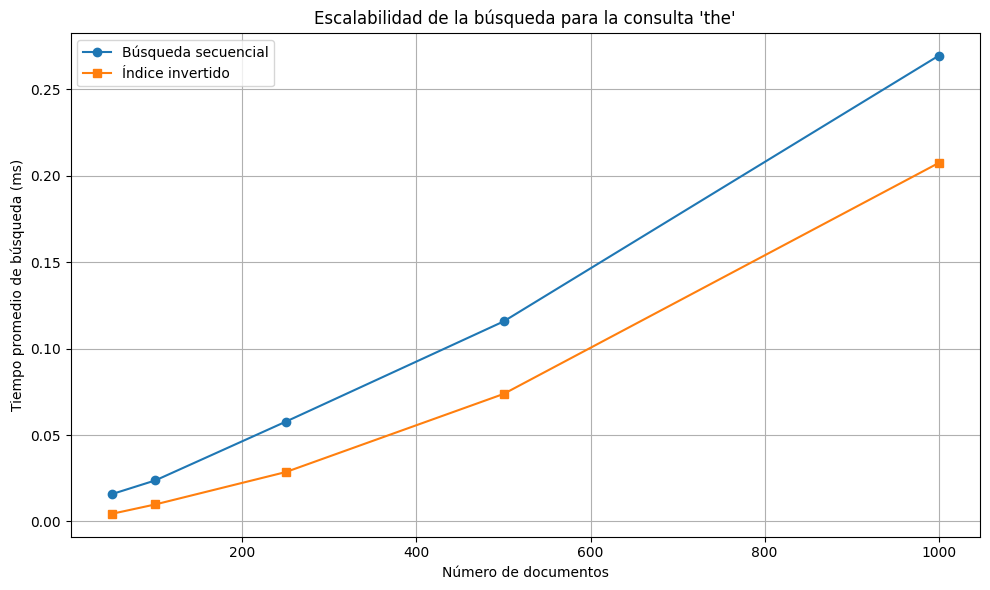

In [ ]:

# Gráfica comparativa: tiempo promedio frente al número de documentos

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    df_escalabilidad["Documentos"],
    df_escalabilidad["Tiempo secuencial (ms)"],
    marker="o",
    label="Búsqueda secuencial"
)

plt.plot(
    df_escalabilidad["Documentos"],
    df_escalabilidad["Tiempo índice (ms)"],
    marker="s",
    label="Índice invertido"
)

plt.xlabel("Número de documentos")
plt.ylabel("Tiempo promedio de búsqueda (ms)")
plt.title(f"Escalabilidad de la búsqueda para la consulta '{CONSULTA_ESCALABILIDAD}'")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## 9. Estimación de una función de tiempo

In [ ]:

# Punto 9. Ajuste lineal t(n) = a*n + b

import numpy as np
import pandas as pd

n = df_escalabilidad["Documentos"].to_numpy(dtype=float)

tiempos = {
    "Búsqueda secuencial":
        df_escalabilidad["Tiempo secuencial (ms)"].to_numpy(dtype=float),
    "Índice invertido":
        df_escalabilidad["Tiempo índice (ms)"].to_numpy(dtype=float)
}

ajustes = {}

for nombre, y in tiempos.items():
    # Ajuste lineal: y = a*n + b
    a, b = np.polyfit(n, y, 1)

    # Predicciones del modelo
    y_estimado = a * n + b

    # Coeficiente de determinación R²
    ss_res = np.sum((y - y_estimado) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else float("nan")

    ajustes[nombre] = {
        "a": a,
        "b": b,
        "r2": r2,
        "predicciones": y_estimado
    }

    print(f"\nMétodo: {nombre}")
    print(f"Modelo: t(n) = {a:.10f} * n + ({b:.8f})")
    print(f"Pendiente a: {a:.10f} ms/documento")
    print(f"Intercepto b: {b:.8f} ms")
    print(f"R²: {r2:.6f}")

tabla_ajustes = pd.DataFrame([
    {
        "Método": nombre,
        "Pendiente a (ms/documento)": datos["a"],
        "Intercepto b (ms)": datos["b"],
        "R²": datos["r2"]
    }
    for nombre, datos in ajustes.items()
])

display(tabla_ajustes)



Método: Búsqueda secuencial
Modelo: t(n) = 0.0002678096 * n + (-0.00529025)
Pendiente a: 0.0002678096 ms/documento
Intercepto b: -0.00529025 ms
R²: 0.993238

Método: Índice invertido
Modelo: t(n) = 0.0002146658 * n + (-0.01677433)
Pendiente a: 0.0002146658 ms/documento
Intercepto b: -0.01677433 ms
R²: 0.979653


,Método,Pendiente a (ms/documento),Intercepto b (ms),R²
0,Búsqueda secuencial,0.000268,-0.005290,0.993238
1,Índice invertido,0.000215,-0.016774,0.979653


## 9.2 Grafica de datos y rectas ajustadas

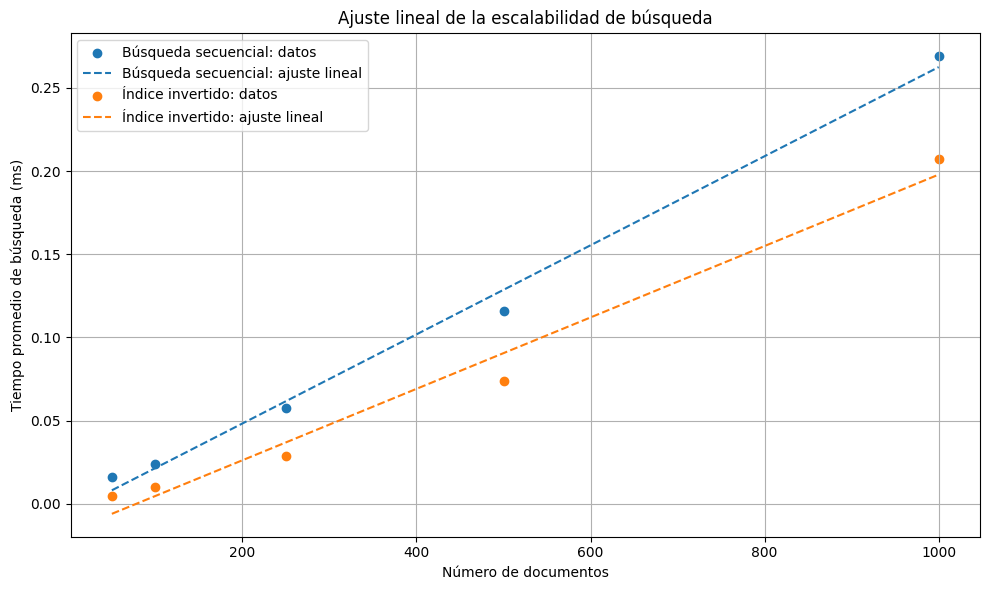

In [ ]:

# Gráfica de tiempos medidos y modelos lineales

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for nombre, y in tiempos.items():
    datos_ajuste = ajustes[nombre]

    # Mediciones experimentales
    plt.scatter(n, y, label=f"{nombre}: datos")

    # Recta ajustada
    plt.plot(
        n,
        datos_ajuste["predicciones"],
        linestyle="--",
        label=f"{nombre}: ajuste lineal"
    )

plt.xlabel("Número de documentos")
plt.ylabel("Tiempo promedio de búsqueda (ms)")
plt.title("Ajuste lineal de la escalabilidad de búsqueda")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Análisis de escalabilidad y ajuste lineal

Se evaluaron la búsqueda secuencial y el índice invertido con corpus de 50, 100, 250, 500 y 1.000 documentos, realizando 30 repeticiones por tamaño. Ambos métodos devolvieron los mismos resultados. Al aumentar el corpus de 50 a 1.000 documentos, el tiempo de búsqueda secuencial pasó de 0,015829 ms a 0,269353 ms, mientras que el índice invertido aumentó de 0,004435 ms a 0,207328 ms.

El índice invertido fue más rápido en todos los tamaños evaluados. Con 50 documentos tardó aproximadamente 3,57 veces menos que la búsqueda secuencial; con 1.000 documentos, la diferencia se redujo a 1,30 veces. Esto se debe, en parte, a que la consulta utilizada fue «the», un término presente en todos los documentos, por lo que el índice debía recuperar una gran cantidad de resultados.

El ajuste lineal de la búsqueda secuencial fue \(t(n)=0,00026781n-0,00529025\), con \(R^2=0,993238\). Para el índice invertido se obtuvo \(t(n)=0,00021467n-0,01677433\), con \(R^2=0,979653\). Ambos modelos representan adecuadamente la tendencia observada, aunque son aproximaciones limitadas a los tamaños analizados.

La construcción del índice para 1.000 documentos tardó aproximadamente 15,73 segundos, mientras que la carga y el procesamiento requirieron 59,76 segundos. Aunque el índice necesita tiempo de construcción y memoria adicional, resulta conveniente cuando se realizan múltiples consultas. En conclusión, ambos métodos fueron correctos, pero el índice invertido presentó menores tiempos de búsqueda en las pruebas realizadas.